In [148]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.metrics import roc_curve, auc

from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.cluster import KMeans
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense

from sklearn.model_selection import GridSearchCV
from sklearn.metrics import silhouette_score

from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import roc_curve, auc

In [149]:
df = pd.read_csv("3.csv")

# Pre-Processing

In [150]:
df.shape

(1500, 9)

In [151]:
df.head(20)

,Age,Income,Gender,Marital_Status,Credit_Score,Num_Purchases,Membership_Years,Device_Used,Churn
0,56.0,70201.189680,Female,Married,687.761776,9,12,Desktop,0
1,69.0,51901.897395,Male,Single,712.617115,3,14,Tablet,0
2,46.0,38605.409293,Male,Married,782.299643,5,8,Mobile,0
3,32.0,49949.736955,Female,Single,697.749518,7,1,Tablet,0
4,NaN,48965.290095,Other,Married,663.155216,4,4,Desktop,1
5,25.0,11326.768555,Female,Divorced,697.061084,1,4,Desktop,1
6,38.0,41579.497114,NaN,Divorced,687.615220,5,6,Tablet,1
7,56.0,54713.055994,Female,Married,714.708713,7,12,Tablet,0
8,36.0,43636.766522,Male,Divorced,540.098369,3,12,Desktop,0
9,40.0,40306.859573,Male,Divorced,NaN,3,2,Mobile,0


In [152]:
df.nunique()

Age                   52
Income              1425
Gender                 3
Marital_Status         3
Credit_Score        1425
Num_Purchases         15
Membership_Years      14
Device_Used            3
Churn                  2
dtype: int64

In [153]:
############## Target Column : Churm ###################

In [154]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Age               1425 non-null   float64
 1   Income            1425 non-null   float64
 2   Gender            1425 non-null   str    
 3   Marital_Status    1500 non-null   str    
 4   Credit_Score      1425 non-null   float64
 5   Num_Purchases     1500 non-null   int64  
 6   Membership_Years  1500 non-null   int64  
 7   Device_Used       1500 non-null   str    
 8   Churn             1500 non-null   int64  
dtypes: float64(3), int64(3), str(3)
memory usage: 105.6 KB


In [155]:
#Selecting categoricalfeatures
categorical_data=df.select_dtypes(include= 'object')

#append the features of categorical_data to list
categorical_features=categorical_data.columns.tolist()

C:\Users\akibz\AppData\Local\Temp\ipykernel_31356\4242615595.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_data=df.select_dtypes(include= 'object')


In [156]:
#Selecting numerical features
numerical_data=df.select_dtypes(include= ['float64' , 'int64'])

#append the features of nummerical_data to list
numerical_features=numerical_data.columns.tolist()

## Numerical Features

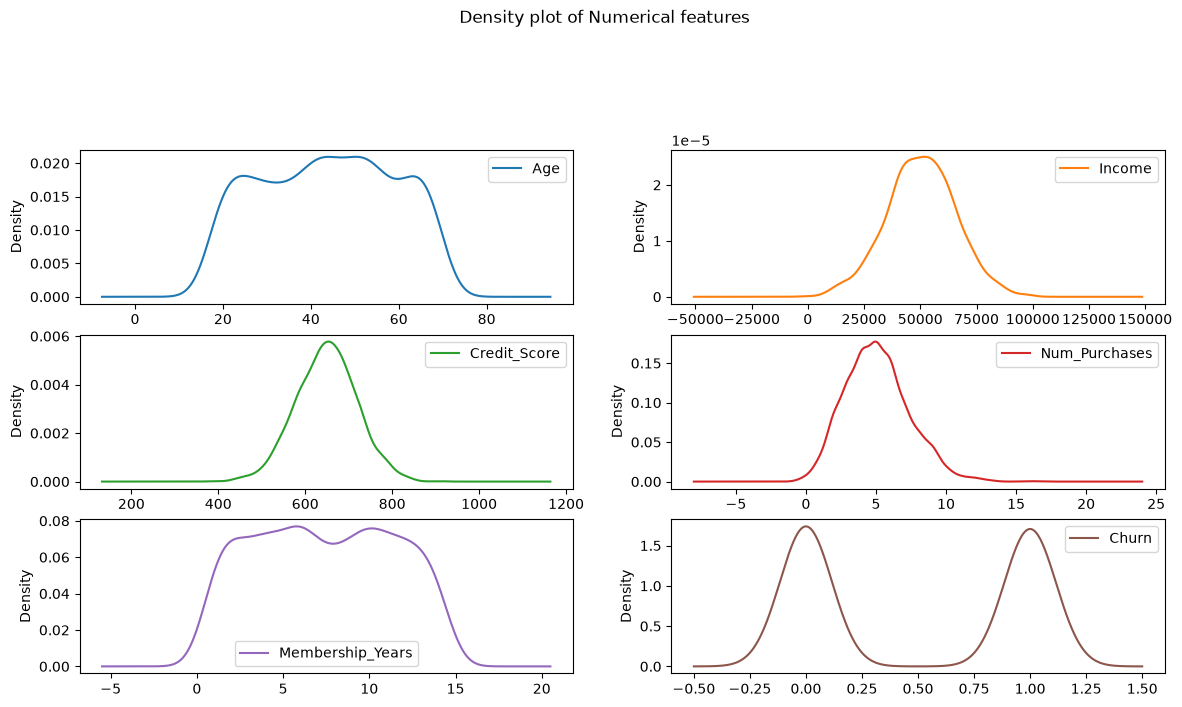

In [157]:
numerical_data.plot(
    kind='density',
    figsize=(14,14),
    subplots=True,
    layout=(6,2),
    title="Density plot of Numerical features",
    sharex=False
)

plt.savefig("density_plot.png", dpi=300, bbox_inches="tight")
plt.show()

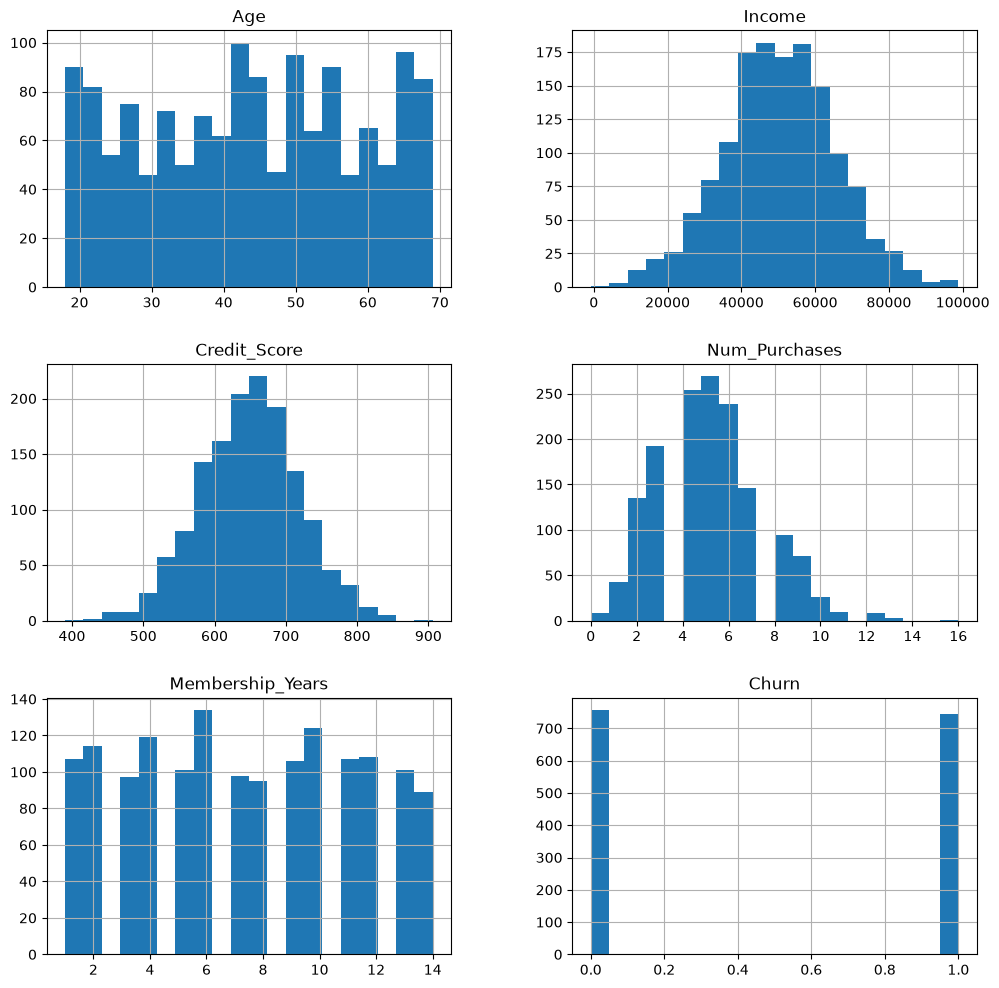

In [158]:
numerical_data.hist(figsize=(12,12),bins=20)
plt.savefig("422 boxplot.png", dpi=300, bbox_inches="tight")
plt.show()


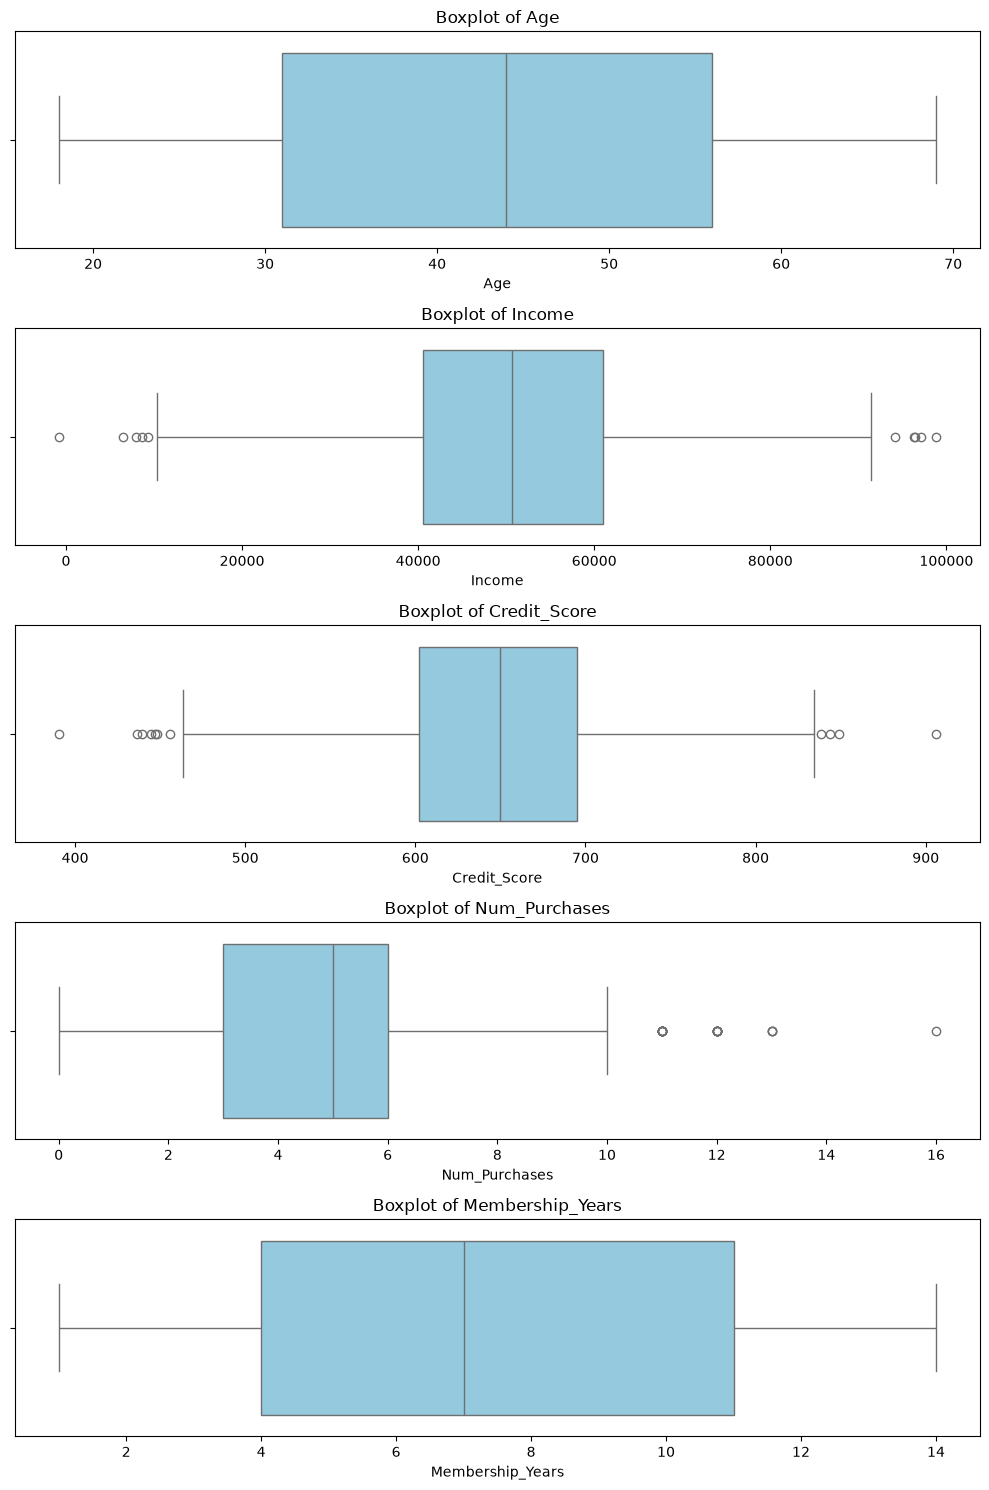

In [159]:
n = [
    "Age", "Income", "Credit_Score",
    "Num_Purchases", "Membership_Years"
    ]

plt.figure(figsize=(10, 15))

for i, col in enumerate(n, 1):
    plt.subplot(len(n), 1, i)
    sns.boxplot(x=df[col], color='skyblue')
    plt.title(f'Boxplot of {col}', fontsize=12)

plt.tight_layout()
plt.savefig("422 boxplot.png", dpi=300, bbox_inches="tight")
plt.show()

In [160]:
df["Income"].min()

np.float64(-826.4212398458985)

In [161]:
###### Income has negative values #######

In [162]:
(df["Income"] <0).sum()

np.int64(1)

In [163]:
df[df["Income"]<0]

,Age,Income,Gender,Marital_Status,Credit_Score,Num_Purchases,Membership_Years,Device_Used,Churn
593,24.0,-826.42124,Female,Divorced,542.911696,5,11,Tablet,1


In [164]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Age               1425 non-null   float64
 1   Income            1425 non-null   float64
 2   Gender            1425 non-null   str    
 3   Marital_Status    1500 non-null   str    
 4   Credit_Score      1425 non-null   float64
 5   Num_Purchases     1500 non-null   int64  
 6   Membership_Years  1500 non-null   int64  
 7   Device_Used       1500 non-null   str    
 8   Churn             1500 non-null   int64  
dtypes: float64(3), int64(3), str(3)
memory usage: 105.6 KB


In [165]:
df = df[df["Income"].isna() | (df["Income"] >= 0)] # Dropped row with negative income value

In [166]:
df.info()

<class 'pandas.DataFrame'>
Index: 1499 entries, 0 to 1499
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Age               1424 non-null   float64
 1   Income            1424 non-null   float64
 2   Gender            1424 non-null   str    
 3   Marital_Status    1499 non-null   str    
 4   Credit_Score      1424 non-null   float64
 5   Num_Purchases     1499 non-null   int64  
 6   Membership_Years  1499 non-null   int64  
 7   Device_Used       1499 non-null   str    
 8   Churn             1499 non-null   int64  
dtypes: float64(3), int64(3), str(3)
memory usage: 117.1 KB


## Co-relation Heatmap

In [167]:
num_cols = df.select_dtypes(include="number")
corr_matrix = num_cols.corr()

In [168]:
corr_matrix

,Age,Income,Credit_Score,Num_Purchases,Membership_Years,Churn
Age,1.000000,0.012530,-0.012236,0.025833,-0.018215,0.007135
Income,0.012530,1.000000,0.009945,-0.009718,0.011695,0.029131
Credit_Score,-0.012236,0.009945,1.000000,0.000832,0.012275,0.021065
Num_Purchases,0.025833,-0.009718,0.000832,1.000000,0.032411,-0.032114
Membership_Years,-0.018215,0.011695,0.012275,0.032411,1.000000,0.000805
Churn,0.007135,0.029131,0.021065,-0.032114,0.000805,1.000000


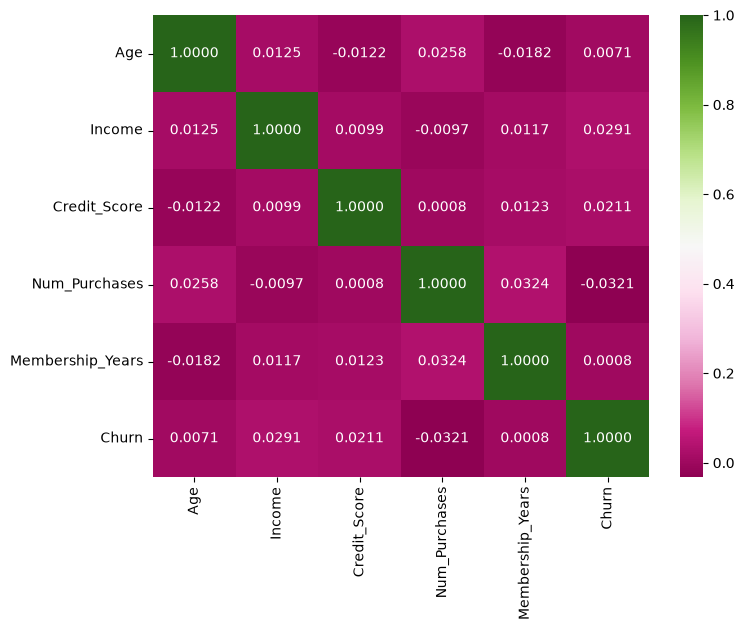

In [169]:
plt.figure(figsize=(8, 6))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".4f",
    cmap="PiYG"
)
plt.savefig("422 heatmap.png", dpi=300, bbox_inches="tight")

plt.show()

In [170]:
############# There is a very low linear realtionship for any numerical feature and churn as all the values are near to zero ###############
############# No feature is highly correlated with more than one feature ###############

## Categorical features

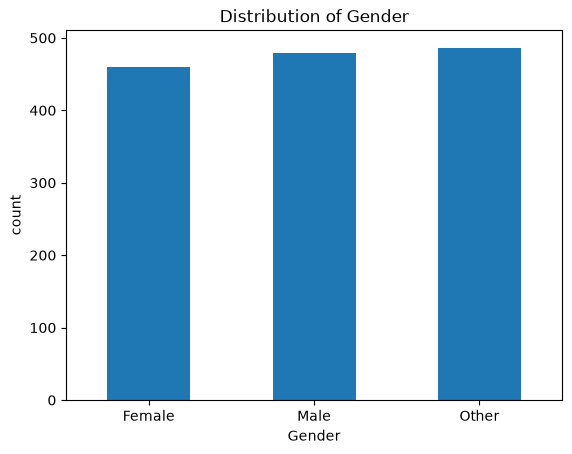

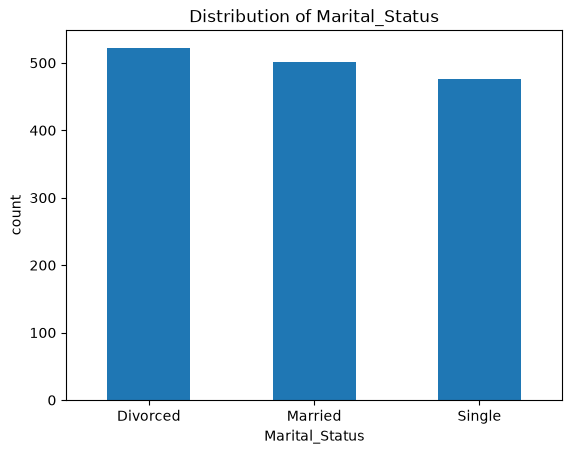

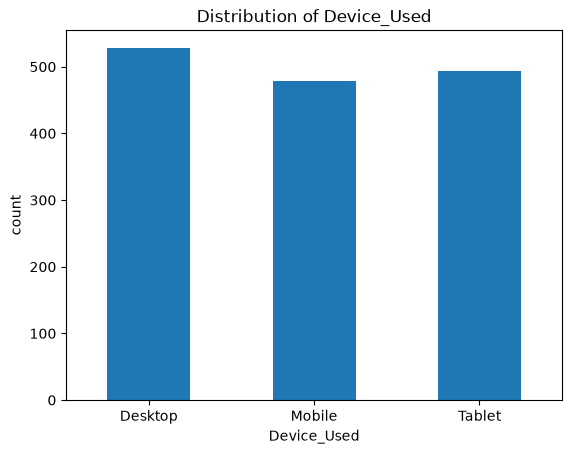

In [171]:
for col in categorical_features:
    plt.title(f'Distribution of {col}')
    categorical_data[col].value_counts().sort_index().plot(kind='bar', rot=0, xlabel=col,ylabel='count')
    plt.show()

In [172]:
######## All categorical features are well balanced ##########

In [173]:
df.groupby("Device_Used")["Churn"].mean() * 100

Device_Used
Desktop    46.022727
Mobile     52.092050
Tablet     50.709939
Name: Churn, dtype: float64

In [174]:
df.groupby("Device_Used")[[
    "Age",
    "Income",
    "Credit_Score",
    "Num_Purchases",
    "Membership_Years"
]].mean()

,Age,Income,Credit_Score,Num_Purchases,Membership_Years
Device_Used,,,,,
Desktop,43.780876,49844.843767,645.343314,4.977273,7.335227
Mobile,43.872247,51288.766724,650.251517,5.027197,7.384937
Tablet,43.641026,50377.447642,651.200188,5.237323,7.442191


In [175]:
print(df["Gender"].unique())

<StringArray>
['Female', 'Male', 'Other', nan]
Length: 4, dtype: str


In [176]:
print(df["Marital_Status"].unique())

<StringArray>
['Married', 'Single', 'Divorced']
Length: 3, dtype: str


In [177]:
print(df["Device_Used"].unique())

<StringArray>
['Desktop', 'Tablet', 'Mobile']
Length: 3, dtype: str


In [178]:
df['Device_Used'] = df['Device_Used'].replace({  # Combined Mobile and Tablet into Portable
    'Desktop' : 'Desktop',
    'Mobile' : 'Portable',
    'Tablet' : 'Portable',
    })

In [179]:
df.head(5)

,Age,Income,Gender,Marital_Status,Credit_Score,Num_Purchases,Membership_Years,Device_Used,Churn
0,56.0,70201.189680,Female,Married,687.761776,9,12,Desktop,0
1,69.0,51901.897395,Male,Single,712.617115,3,14,Portable,0
2,46.0,38605.409293,Male,Married,782.299643,5,8,Portable,0
3,32.0,49949.736955,Female,Single,697.749518,7,1,Portable,0
4,NaN,48965.290095,Other,Married,663.155216,4,4,Desktop,1


## Churn vs Other Features

In [180]:
#check Imbalance in data

#group instances based on the classes in Churn variable
class_counts=df.groupby("Churn").size()

columns=['Churn','count','percentage']
Churn=[0,1]
count=list()
percentage=list()

#Calculate the percentage of each value of the Churn variable from total
for val in range(2):
    count.append(class_counts[val])
    percent=(class_counts[val]/1500)*100
    percentage.append(percent)

# Convert the calulated values into a dataframe
imbalance_df=pd.DataFrame(list(zip(Churn,count,percentage)),columns=columns)
imbalance_df

,Churn,count,percentage
0,0,757,50.466667
1,1,742,49.466667


## Splitting the dataset

In [181]:
############ Target feature Churn is well balanced #################

In [182]:
df.groupby("Churn").mean(numeric_only=True)

,Age,Income,Credit_Score,Num_Purchases,Membership_Years
Churn,,,,,
0,43.657343,50043.203002,647.396536,5.150594,7.383091
1,43.871650,50932.349578,650.325753,5.005391,7.389488


In [183]:
x = df.drop('Churn', axis=1)
y = df['Churn']

In [184]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

## Fixing Missing Values and Duplicates

In [185]:
df.isnull().sum()

Age                 75
Income              75
Gender              75
Marital_Status       0
Credit_Score        75
Num_Purchases        0
Membership_Years     0
Device_Used          0
Churn                0
dtype: int64

In [186]:
############# Age, Income, Gender, Credit_score have null values ##############

In [187]:
df.duplicated().sum()

np.int64(0)

In [188]:
############ No Duplicate Rows ############

#### Fix creidit_score missing values

In [189]:
df["Credit_Score"].describe()

count    1424.000000
mean      648.861145
std        69.551508
min       390.384237
25%       602.104919
50%       650.022382
75%       694.991115
max       906.039126
Name: Credit_Score, dtype: float64

In [190]:
df["Credit_Score"].skew() 

np.float64(-0.05900168861992506)

In [191]:
############ Credit_Score is symmetric ############

In [192]:
impute_cs = SimpleImputer(missing_values=np.nan, strategy='mean')
x_train["Credit_Score"] = impute_cs.fit_transform(
    x_train[["Credit_Score"]]
)
x_test["Credit_Score"] = impute_cs.transform(
    x_test[["Credit_Score"]]
)

#### Fix Age missing values

In [193]:
df["Age"].skew() 

np.float64(-0.04292939320550584)

In [194]:
impute_ag = SimpleImputer(missing_values=np.nan, strategy='mean')
x_train["Age"] = impute_ag.fit_transform(
    x_train[["Age"]]
)
x_test["Age"] = impute_ag.transform(
    x_test[["Age"]]
)

#### Fix Income missing values

In [195]:
df["Income"].skew() 

np.float64(-0.009893267517785753)

In [196]:
impute_in = SimpleImputer(missing_values=np.nan, strategy='mean')
x_train["Income"] = impute_in.fit_transform(
    x_train[["Income"]]
)
x_test["Income"] = impute_in.transform(
    x_test[["Income"]]
)

#### Fix Gender missing values

In [197]:
impute_gen = SimpleImputer(missing_values=np.nan, strategy='most_frequent')
x_train[["Gender"]] = impute_gen.fit_transform(
    x_train[["Gender"]]
)
x_test[["Gender"]] = impute_gen.transform(
    x_test[["Gender"]]
)

In [198]:
x_test.isnull().sum()

Age                 0
Income              0
Gender              0
Marital_Status      0
Credit_Score        0
Num_Purchases       0
Membership_Years    0
Device_Used         0
dtype: int64

In [199]:
x_train.isnull().sum()

Age                 0
Income              0
Gender              0
Marital_Status      0
Credit_Score        0
Num_Purchases       0
Membership_Years    0
Device_Used         0
dtype: int64

## Encoding

### One Hot Encoding

In [200]:
df.nunique()

Age                   52
Income              1424
Gender                 3
Marital_Status         3
Credit_Score        1424
Num_Purchases         15
Membership_Years      14
Device_Used            2
Churn                  2
dtype: int64

In [201]:
ohe = OneHotEncoder(handle_unknown="ignore",drop='first')

In [202]:
x_train_ohe = ohe.fit_transform(x_train[categorical_features])
x_test_ohe = ohe.transform(x_test[categorical_features])

In [203]:
enc_x_train = pd.DataFrame(x_train_ohe.toarray(), columns=ohe.get_feature_names_out(categorical_features), index=x_train.index)
enc_x_test = pd.DataFrame(x_test_ohe.toarray(), columns=ohe.get_feature_names_out(categorical_features), index=x_test.index)

In [204]:
x_train = x_train.drop(columns=categorical_features)
x_test = x_test.drop(columns=categorical_features)

In [205]:
x_train = pd.concat([x_train,enc_x_train], axis=1)
x_test= pd.concat([x_test,enc_x_test], axis=1)

In [206]:
x_train

,Age,Income,Credit_Score,Num_Purchases,Membership_Years,Gender_Male,Gender_Other,Marital_Status_Married,Marital_Status_Single,Device_Used_Portable
382,54.0,50957.844520,718.094208,8,5,0.0,0.0,1.0,0.0,0.0
538,69.0,37625.474346,649.961059,9,8,1.0,0.0,0.0,0.0,1.0
1493,62.0,75530.827310,689.148458,8,14,0.0,0.0,1.0,0.0,0.0
1113,27.0,47479.174015,741.208985,2,10,0.0,0.0,1.0,0.0,0.0
324,42.0,74899.214041,592.375643,4,3,1.0,0.0,1.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...
1131,48.0,55017.488027,637.846464,4,4,0.0,1.0,0.0,1.0,1.0
1295,63.0,52844.421850,705.170048,9,9,0.0,0.0,0.0,1.0,0.0
861,20.0,33897.984834,646.069841,7,13,0.0,1.0,1.0,0.0,0.0
1460,47.0,54590.215970,588.972056,4,11,0.0,0.0,0.0,1.0,1.0


In [207]:
x_train.shape

(1199, 10)

In [208]:
x_test

,Age,Income,Credit_Score,Num_Purchases,Membership_Years,Gender_Male,Gender_Other,Marital_Status_Married,Marital_Status_Single,Device_Used_Portable
1117,57.00000,56974.712446,663.154030,7,5,0.0,1.0,0.0,0.0,1.0
1396,43.90581,39937.459449,555.949996,5,7,1.0,0.0,0.0,0.0,0.0
422,59.00000,63122.516574,645.634146,7,8,0.0,0.0,0.0,0.0,0.0
413,43.00000,61293.135164,628.446836,5,11,0.0,0.0,1.0,0.0,1.0
451,39.00000,33349.428424,803.004587,0,7,0.0,1.0,0.0,1.0,1.0
...,...,...,...,...,...,...,...,...,...,...
984,41.00000,35722.242880,575.364830,6,4,0.0,0.0,0.0,1.0,1.0
800,27.00000,50823.418667,605.950905,7,5,0.0,0.0,1.0,0.0,0.0
1354,49.00000,71178.147783,644.148250,5,2,0.0,0.0,1.0,0.0,0.0
1150,54.00000,51886.267588,538.323057,4,8,1.0,0.0,0.0,0.0,1.0


In [209]:
x_test.shape

(300, 10)

## Scaling

In [210]:
scaler = StandardScaler()

In [211]:
scaler.fit(x_train)
x_train_scaled = scaler.transform(x_train)
x_test_scaled = scaler.transform(x_test)

In [212]:
x_train_scaled

array([[ 0.69024132,  0.0090362 ,  1.0128825 , ...,  1.38979867,
        -0.67330033, -1.3519727 ],
       [ 1.71594222, -0.88717465,  0.00597098, ..., -0.71952868,
        -0.67330033,  0.7396599 ],
       [ 1.2372818 ,  1.66084855,  0.58510529, ...,  1.38979867,
        -0.67330033, -1.3519727 ],
       ...,
       [-1.63468071, -1.137739  , -0.05153572, ...,  1.38979867,
        -0.67330033, -1.3519727 ],
       [ 0.21158091,  0.25320664, -0.89536018, ..., -0.71952868,
         1.48522131,  0.7396599 ],
       [-0.19869945, -1.09354175, -1.24590622, ..., -0.71952868,
        -0.67330033, -1.3519727 ]], shape=(1199, 10))

In [213]:
x_test_scaled

array([[ 8.95381504e-01,  4.13494087e-01,  2.00944417e-01, ...,
        -7.19528678e-01, -6.73300329e-01,  7.39659904e-01],
       [-4.85869547e-16, -7.31761468e-01, -1.38337950e+00, ...,
        -7.19528678e-01, -6.73300329e-01, -1.35197270e+00],
       [ 1.03214162e+00,  8.26753597e-01, -5.79746700e-02, ...,
        -7.19528678e-01, -6.73300329e-01, -1.35197270e+00],
       ...,
       [ 3.48341026e-01,  1.36825852e+00, -7.99341135e-02, ...,
         1.38979867e+00, -6.73300329e-01, -1.35197270e+00],
       [ 6.90241325e-01,  7.14454162e-02, -1.64388072e+00, ...,
        -7.19528678e-01, -6.73300329e-01,  7.39659904e-01],
       [ 1.44242198e+00,  1.38454774e+00, -5.29895657e-01, ...,
         1.38979867e+00, -6.73300329e-01,  7.39659904e-01]],
      shape=(300, 10))

# Model Training

## Logisttic Regression

In [214]:
clf = LogisticRegression(max_iter=10000, random_state=42)

In [215]:
clf.fit(x_train_scaled, y_train)

,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",10000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'l

In [216]:
y_pred_clf = clf.predict(x_test_scaled)

## KNN

In [217]:
knn = KNeighborsClassifier()

In [221]:
param_grid = {'n_neighbors': range(1, 21)}

In [222]:
grid_search = GridSearchCV(knn, param_grid, cv=3)
grid_search.fit(x_train_scaled, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",KNeighborsClassifier()
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'n_neighbors': range(1, 21)}"
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",3
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with higherva

In [223]:
optimal_k = grid_search.best_params_['n_neighbors']
print(f"The optimal K value is: {optimal_k}")

The optimal K value is: 1


In [224]:
knn = KNeighborsClassifier(n_neighbors=1)
knn.fit(x_train_scaled, y_train)
y_pred_knn = knn.predict(x_test_scaled)

## K-Means

In [225]:
# Considering the dataset as non labled for Unsupervised Learning

In [226]:
x_us = pd.concat([x_train, x_test], axis=0, ignore_index=True)

In [227]:
x_us.head(5)

,Age,Income,Credit_Score,Num_Purchases,Membership_Years,Gender_Male,Gender_Other,Marital_Status_Married,Marital_Status_Single,Device_Used_Portable
0,54.0,50957.844520,718.094208,8,5,0.0,0.0,1.0,0.0,0.0
1,69.0,37625.474346,649.961059,9,8,1.0,0.0,0.0,0.0,1.0
2,62.0,75530.827310,689.148458,8,14,0.0,0.0,1.0,0.0,0.0
3,27.0,47479.174015,741.208985,2,10,0.0,0.0,1.0,0.0,0.0
4,42.0,74899.214041,592.375643,4,3,1.0,0.0,1.0,0.0,0.0


In [228]:
x_us.shape

(1499, 10)

In [229]:
scaler_us = StandardScaler()

In [230]:
scaler_us.fit(x_us)
x_us_scaled = scaler.transform(x_us)

In [231]:
x_us_scaled

array([[ 0.69024132,  0.0090362 ,  1.0128825 , ...,  1.38979867,
        -0.67330033, -1.3519727 ],
       [ 1.71594222, -0.88717465,  0.00597098, ..., -0.71952868,
        -0.67330033,  0.7396599 ],
       [ 1.2372818 ,  1.66084855,  0.58510529, ...,  1.38979867,
        -0.67330033, -1.3519727 ],
       ...,
       [ 0.34834103,  1.36825852, -0.07993411, ...,  1.38979867,
        -0.67330033, -1.3519727 ],
       [ 0.69024132,  0.07144542, -1.64388072, ..., -0.71952868,
        -0.67330033,  0.7396599 ],
       [ 1.44242198,  1.38454774, -0.52989566, ...,  1.38979867,
        -0.67330033,  0.7396599 ]], shape=(1499, 10))

In [232]:
x_us_scaled_df = pd.DataFrame(
    x_us_scaled,
    columns=x_us.columns,
    index=x_us.index
)

In [233]:
x_us_scaled_df.head(5)

,Age,Income,Credit_Score,Num_Purchases,Membership_Years,Gender_Male,Gender_Other,Marital_Status_Married,Marital_Status_Single,Device_Used_Portable
0,0.690241,0.009036,1.012883,1.305741,-0.599848,-0.689046,-0.782022,1.389799,-0.6733,-1.351973
1,1.715942,-0.887175,0.005971,1.753690,0.158821,1.451281,-0.782022,-0.719529,-0.6733,0.739660
2,1.237282,1.660849,0.585105,1.305741,1.676158,-0.689046,-0.782022,1.389799,-0.6733,-1.351973
3,-1.156020,-0.224802,1.354486,-1.381955,0.664600,-0.689046,-0.782022,1.389799,-0.6733,-1.351973
4,-0.130319,1.618391,-0.845060,-0.486057,-1.105627,1.451281,-0.782022,1.389799,-0.6733,-1.351973


In [234]:
k_range = range(1,30)
SSE = []
for k in k_range:
  km = KMeans(n_clusters= k)
  km.fit(x_us_scaled)  
  SSE.append(km.inertia_)

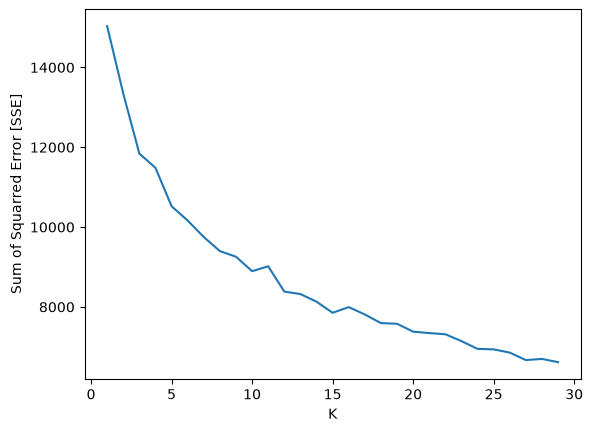

In [235]:
plt.xlabel("K")
plt.ylabel("Sum of Squarred Error [SSE]")
plt.plot(k_range,SSE)

In [236]:
# No elbow point

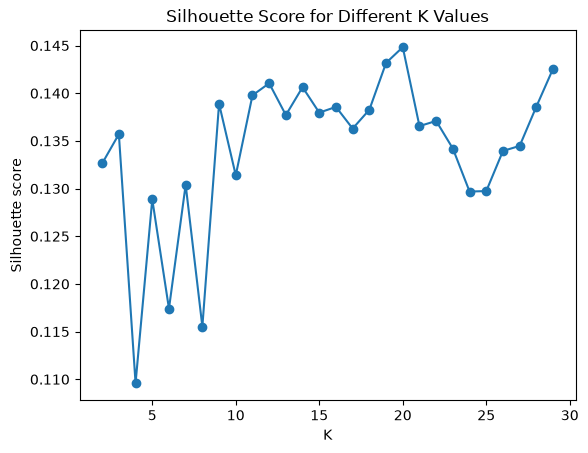

In [237]:
scores = []

for k in range(2, 30):
    kmeans = KMeans(n_clusters=k, random_state=42)
    labels = kmeans.fit_predict(x_us_scaled)
    score = silhouette_score(x_us_scaled, labels)
    scores.append(score)

# plot
plt.plot(range(2, 30), scores, marker='o')
plt.xlabel("K")
plt.ylabel("Silhouette score")
plt.title("Silhouette Score for Different K Values")
plt.savefig("422 shil.png", dpi=300, bbox_inches="tight")
plt.show()

In [238]:
for k, score in zip(range(2, 30), scores):
    print(f"K={k}: {score:.3f}")

K=2: 0.133
K=3: 0.136
K=4: 0.110
K=5: 0.129
K=6: 0.117
K=7: 0.130
K=8: 0.116
K=9: 0.139
K=10: 0.131
K=11: 0.140
K=12: 0.141
K=13: 0.138
K=14: 0.141
K=15: 0.138
K=16: 0.139
K=17: 0.136
K=18: 0.138
K=19: 0.143
K=20: 0.145
K=21: 0.137
K=22: 0.137
K=23: 0.134
K=24: 0.130
K=25: 0.130
K=26: 0.134
K=27: 0.134
K=28: 0.139
K=29: 0.143


In [239]:
# taking Best k = 11

In [240]:
kmeans = KMeans(n_clusters=11, random_state=42, n_init=10)
y_predicted_km = kmeans.fit_predict(x_us_scaled)

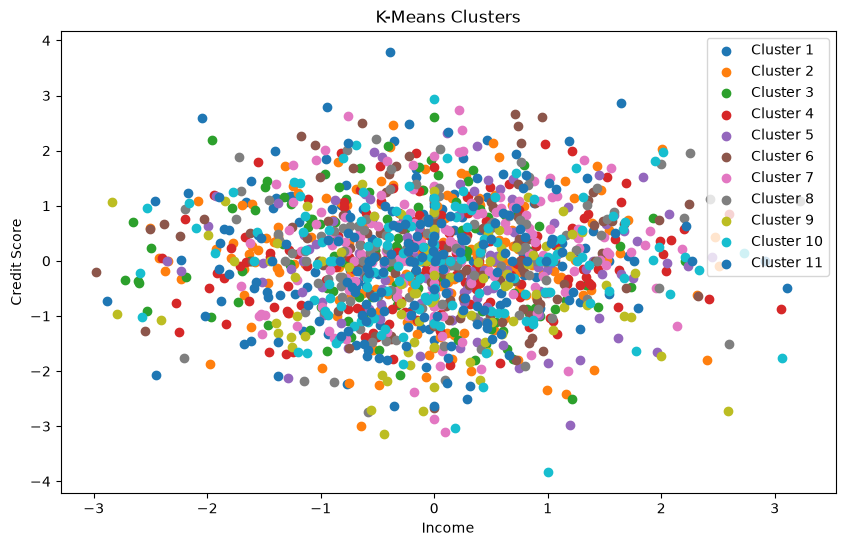

In [241]:
x_us_scaled_df['Cluster'] = y_predicted_km

plt.figure(figsize=(10, 6))

for i in range(11):
    cluster_data = x_us_scaled_df[
        x_us_scaled_df['Cluster'] == i
    ]

    plt.scatter(
        cluster_data['Income'],
        cluster_data['Credit_Score'],
        label=f'Cluster {i+1}'
    )

plt.xlabel('Income')
plt.ylabel('Credit Score')
plt.title('K-Means Clusters')
plt.legend()
plt.savefig("422 clus.png", dpi=300, bbox_inches="tight")
plt.show()

## Neural Network

In [242]:
model = Sequential([
    Dense(16, activation='relu', input_shape=(x_train_scaled.shape[1],)),
    Dense(8, activation='relu'),
    Dense(1, activation='sigmoid')
])

D:\conda_envs\tensorflow\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [243]:
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

In [244]:
history = model.fit(
    x_train_scaled,
    y_train,
    epochs=100,
    batch_size=32
)

Epoch 1/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.4954 - loss: 0.7178
Epoch 2/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.4971 - loss: 0.7049
Epoch 3/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.5038 - loss: 0.7007
Epoch 4/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.5071 - loss: 0.6971
Epoch 5/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5063 - loss: 0.6950
Epoch 6/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.5129 - loss: 0.6941
Epoch 7/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.5188 - loss: 0.6915
Epoch 8/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.5213 - loss: 0.6903
Epoch 9/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5271 - loss: 0.6890
Epoch 10/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.5321 - loss: 0.6879
Epoch 11/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.5413 - loss: 0.6870
Epoch 12/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy:

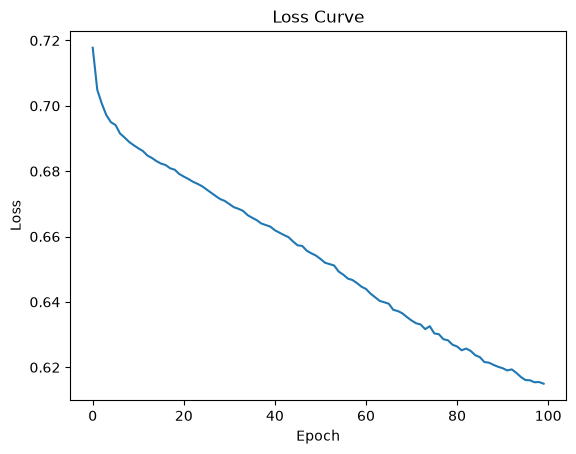

10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.5400 - loss: 0.7408  
Testing Accuracy: 54.0%


In [245]:
plt.plot(history.history['loss'])
plt.title("Loss Curve")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.show()

#Print test error
print(f"Testing Accuracy: {round(model.evaluate(x_test_scaled, y_test)[1] * 100, 2)}%")

In [246]:
y_prob_nn = model.predict(x_test_scaled)
y_pred_nn = (y_prob_nn >= 0.5).astype(int).flatten()

10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step


# Evaluation

## Confusion Matrix

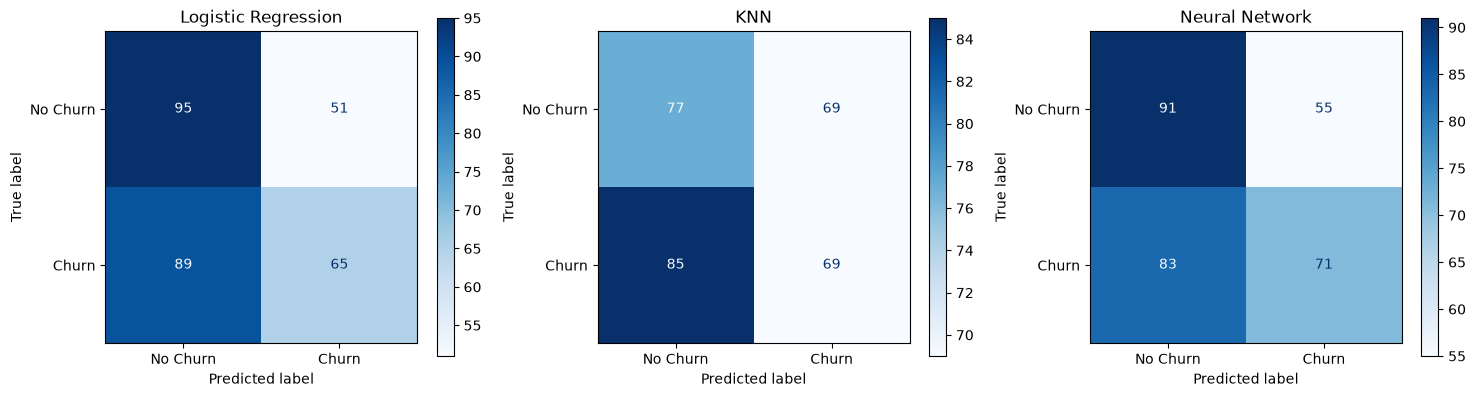

In [247]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Logistic Regression
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_clf,
    display_labels=["No Churn", "Churn"],
    cmap="Blues",
    ax=axes[0]
)
axes[0].set_title("Logistic Regression")

# KNN
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_knn,
    display_labels=["No Churn", "Churn"],
    cmap="Blues",
    ax=axes[1]
)
axes[1].set_title("KNN")

# Neural Network
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_nn,
    display_labels=["No Churn", "Churn"],
    cmap="Blues",
    ax=axes[2]
)
axes[2].set_title("Neural Network")

plt.tight_layout()
plt.show()

## Accuracy, Precision, Recall, F1 Score

In [104]:
print("=== Logistic Regression ===")
print(classification_report(
    y_test,
    y_pred_clf,
    target_names=["No Churn", "Churn"]
))

print("\n=== KNN ===")
print(classification_report(
    y_test,
    y_pred_knn,
    target_names=["No Churn", "Churn"]
))

print("\n=== Neural Network ===")
print(classification_report(
    y_test,
    y_pred_nn,
    target_names=["No Churn", "Churn"]
))

=== Logistic Regression ===
              precision    recall  f1-score   support

    No Churn       0.52      0.65      0.58       146
       Churn       0.56      0.42      0.48       154

    accuracy                           0.53       300
   macro avg       0.54      0.54      0.53       300
weighted avg       0.54      0.53      0.53       300


=== KNN ===
              precision    recall  f1-score   support

    No Churn       0.48      0.53      0.50       146
       Churn       0.50      0.45      0.47       154

    accuracy                           0.49       300
   macro avg       0.49      0.49      0.49       300
weighted avg       0.49      0.49      0.49       300


=== Neural Network ===
              precision    recall  f1-score   support

    No Churn       0.46      0.52      0.49       146
       Churn       0.49      0.43      0.46       154

    accuracy                           0.47       300
   macro avg       0.47      0.47      0.47       300
weighted 

## AUC score, ROC curve

In [109]:
y_probs = model.predict(x_test_scaled).ravel()

10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step 


In [107]:
models = {
    "Logistic Regression": clf,
    "KNN": knn,
    "Neural Network": model
}

10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step  


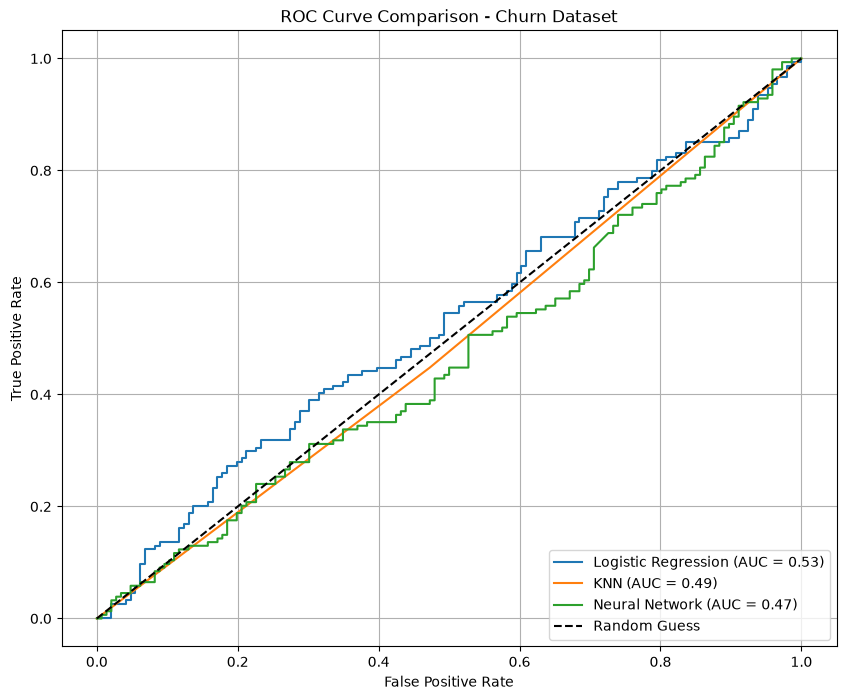

In [147]:
plt.figure(figsize=(10, 8))


y_probs = clf.predict_proba(x_test_scaled)[:, 1]

fpr, tpr, _ = roc_curve(y_test, y_probs)
roc_auc = auc(fpr, tpr)

plt.plot(fpr, tpr, label=f"Logistic Regression (AUC = {roc_auc:.2f})")



y_probs = knn.predict_proba(x_test_scaled)[:, 1]

fpr, tpr, _ = roc_curve(y_test, y_probs)
roc_auc = auc(fpr, tpr)

plt.plot(fpr, tpr, label=f"KNN (AUC = {roc_auc:.2f})")



y_probs = model.predict(x_test_scaled).ravel()

fpr, tpr, _ = roc_curve(y_test, y_probs)
roc_auc = auc(fpr, tpr)

plt.plot(fpr, tpr, label=f"Neural Network (AUC = {roc_auc:.2f})")



plt.plot([0, 1], [0, 1], 'k--', label="Random Guess")



plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison - Churn Dataset")
plt.legend(loc="lower right")
plt.grid()
plt.show()